# Visualizations for the Final Presentation


## 1. Load the data

In [2]:
from google.colab import drive
drive.mount("/content/drive")

from pathlib import Path
import pandas as pd
import numpy as np

# Change this path to your Google Drive folder.
from pathlib import Path

DATA_DIR = Path(
    "/content/drive/MyDrive/Clubs/sheCodes/Fall 2026 SLP/Team Lead/Spaceship_Titanic_Data"
)

train = pd.read_csv(DATA_DIR / "train.csv")
test = pd.read_csv(DATA_DIR / "test.csv")

print("Training data:", train.shape)
print("Test data:", test.shape)
display(train.head())

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Training data: (8693, 14)
Test data: (4277, 13)


,PassengerId,HomePlanet,CryoSleep,Cabin,Destination,Age,VIP,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck,Name,Transported
0,0001_01,Europa,False,B/0/P,TRAPPIST-1e,39.0,False,0.0,0.0,0.0,0.0,0.0,Maham Ofracculy,False
1,0002_01,Earth,False,F/0/S,TRAPPIST-1e,24.0,False,109.0,9.0,25.0,549.0,44.0,Juanna Vines,True
2,0003_01,Europa,False,A/0/S,TRAPPIST-1e,58.0,True,43.0,3576.0,0.0,6715.0,49.0,Altark Susent,False
3,0003_02,Europa,False,A/0/S,TRAPPIST-1e,33.0,False,0.0,1283.0,371.0,3329.0,193.0,Solam Susent,False
4,0004_01,Earth,False,F/1/S,TRAPPIST-1e,16.0,False,303.0,70.0,151.0,565.0,2.0,Willy Santantines,True


## 2. Import visualization tools and create a consistent style

In [3]:
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.ticker import PercentFormatter

sns.set_theme(style="whitegrid", context="talk")

COLORS = {
    "transported": "#2A9D8F",
    "not_transported": "#E76F51",
    "navy": "#264653",
    "gold": "#E9C46A",
    "blue": "#457B9D",
    "purple": "#7B2CBF"
}

plt.rcParams["figure.dpi"] = 120
plt.rcParams["savefig.dpi"] = 200
plt.rcParams["axes.titleweight"] = "bold"
plt.rcParams["axes.titlepad"] = 16

## 3. Prepare helpful visualization features

In [4]:
visual_data = train.copy()

spending_columns = [
    "RoomService",
    "FoodCourt",
    "ShoppingMall",
    "Spa",
    "VRDeck"
]

visual_data["TotalSpending"] = visual_data[spending_columns].sum(
    axis=1,
    min_count=1
)
visual_data["CabinDeck"] = visual_data["Cabin"].str.split("/").str[0]
visual_data["CabinSide"] = visual_data["Cabin"].str.split("/").str[2]
visual_data["GroupId"] = visual_data["PassengerId"].str.split("_").str[0]
visual_data["GroupSize"] = visual_data["GroupId"].map(
    visual_data["GroupId"].value_counts()
)
visual_data["TransportedLabel"] = visual_data["Transported"].map({
    True: "Transported",
    False: "Not transported"
})

display(visual_data[[
    "TransportedLabel",
    "HomePlanet",
    "CryoSleep",
    "CabinDeck",
    "TotalSpending",
    "GroupSize"
]].head())

,TransportedLabel,HomePlanet,CryoSleep,CabinDeck,TotalSpending,GroupSize
0,Not transported,Europa,False,B,0.0,1
1,Transported,Earth,False,F,736.0,1
2,Not transported,Europa,False,A,10383.0,2
3,Not transported,Europa,False,A,5176.0,2
4,Transported,Earth,False,F,1091.0,1


## 4. Chart 1: Who was transported?

This donut chart gives the audience an immediate understanding of the target variable and class balance.

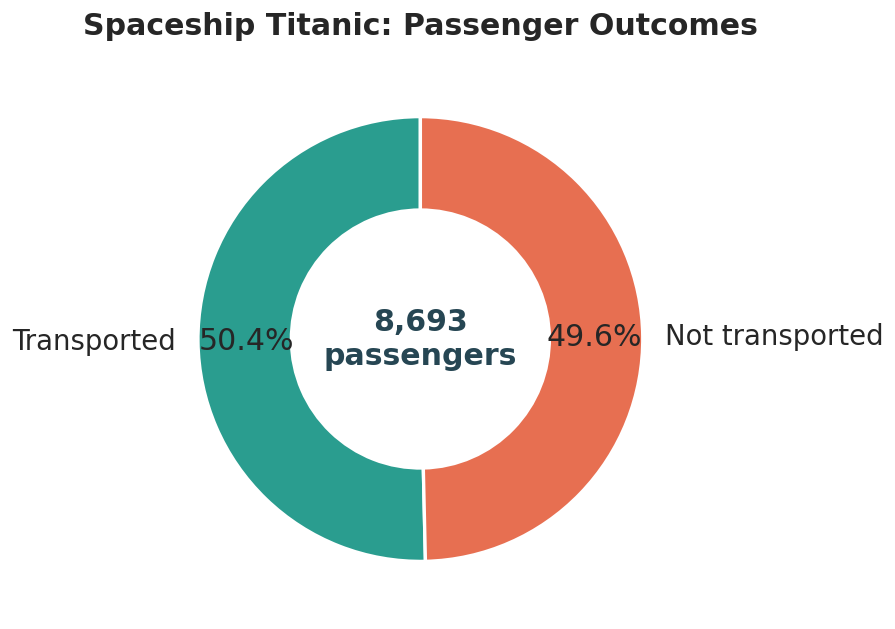

In [5]:
outcome_counts = visual_data["TransportedLabel"].value_counts()
labels = outcome_counts.index
values = outcome_counts.values
colors = [COLORS["transported"], COLORS["not_transported"]]

fig, ax = plt.subplots(figsize=(7, 6))
ax.pie(
    values,
    labels=labels,
    colors=colors,
    autopct="%1.1f%%",
    startangle=90,
    pctdistance=0.78,
    wedgeprops={"width": 0.42, "edgecolor": "white", "linewidth": 2}
)
ax.text(
    0, 0,
    f"{len(visual_data):,}\npassengers",
    ha="center",
    va="center",
    fontsize=18,
    fontweight="bold",
    color=COLORS["navy"]
)
ax.set_title("Spaceship Titanic: Passenger Outcomes")
plt.tight_layout()
plt.savefig(DATA_DIR / "presentation_01_outcome_donut.png", bbox_inches="tight")
plt.show()

## 5. Chart 2: Transportation rate by CryoSleep status

This 100% stacked bar chart compares transported and non-transported passengers within each CryoSleep group.

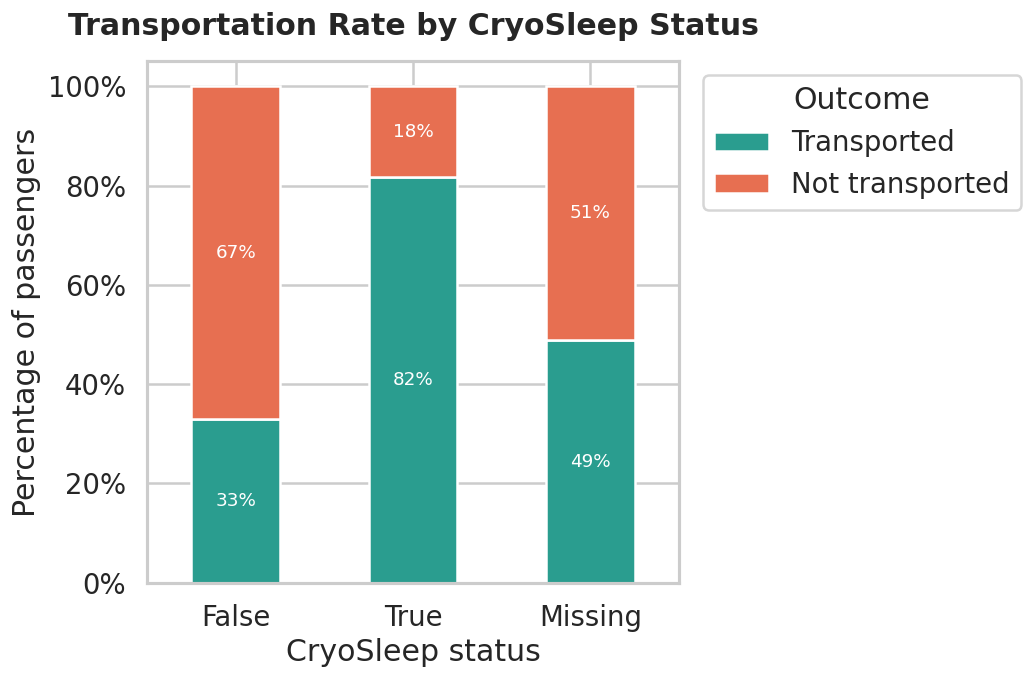

In [6]:
cryosleep_table = pd.crosstab(
    visual_data["CryoSleep"].fillna("Missing"),
    visual_data["TransportedLabel"],
    normalize="index"
)
cryosleep_table = cryosleep_table.reindex(
    columns=["Transported", "Not transported"],
    fill_value=0
)

ax = cryosleep_table.plot(
    kind="bar",
    stacked=True,
    figsize=(9, 6),
    color=[COLORS["transported"], COLORS["not_transported"]]
)
ax.yaxis.set_major_formatter(PercentFormatter(1))
ax.set_title("Transportation Rate by CryoSleep Status")
ax.set_xlabel("CryoSleep status")
ax.set_ylabel("Percentage of passengers")
ax.legend(title="Outcome", bbox_to_anchor=(1.02, 1), loc="upper left")

for container in ax.containers:
    labels = [
        f"{bar.get_height():.0%}" if bar.get_height() >= 0.08 else ""
        for bar in container
    ]
    ax.bar_label(container, labels=labels, label_type="center", color="white", fontsize=11)

plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig(DATA_DIR / "presentation_02_cryosleep_outcomes.png", bbox_inches="tight")
plt.show()

## 6. Chart 3: Transportation rate by cabin deck

Cabin deck is extracted from the original cabin value. This chart shows how a raw text field can become a useful modeling feature.

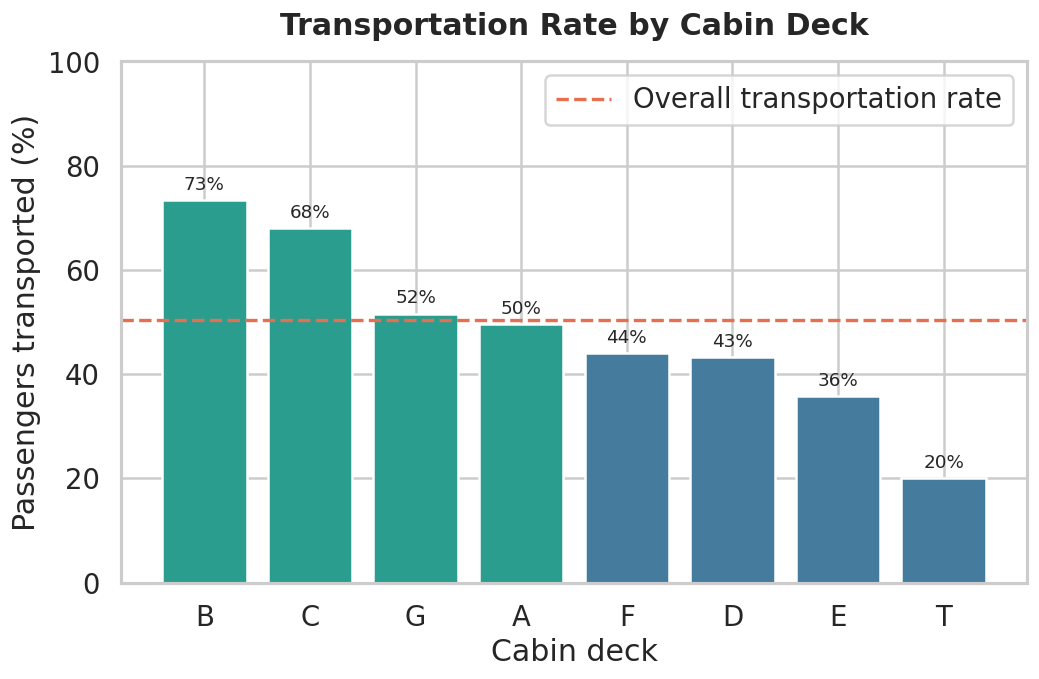

In [7]:
deck_rates = (
    visual_data.dropna(subset=["CabinDeck"])
    .groupby("CabinDeck")["Transported"]
    .mean()
    .sort_values(ascending=False)
    .mul(100)
)

fig, ax = plt.subplots(figsize=(9, 6))
bars = ax.bar(
    deck_rates.index,
    deck_rates.values,
    color=[
        COLORS["transported"] if value >= deck_rates.mean()
        else COLORS["blue"]
        for value in deck_rates.values
    ]
)
ax.axhline(
    visual_data["Transported"].mean() * 100,
    color=COLORS["not_transported"],
    linestyle="--",
    linewidth=2,
    label="Overall transportation rate"
)
ax.set_title("Transportation Rate by Cabin Deck")
ax.set_xlabel("Cabin deck")
ax.set_ylabel("Passengers transported (%)")
ax.set_ylim(0, 100)
ax.legend()

for bar, value in zip(bars, deck_rates.values):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        value + 2,
        f"{value:.0f}%",
        ha="center",
        fontsize=11
    )

plt.tight_layout()
plt.savefig(DATA_DIR / "presentation_03_cabin_deck_rates.png", bbox_inches="tight")
plt.show()

## 7. Chart 4: Spending patterns

This boxplot compares passenger spending for transported and non-transported passengers.

/tmp/ipykernel_4872/536914619.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


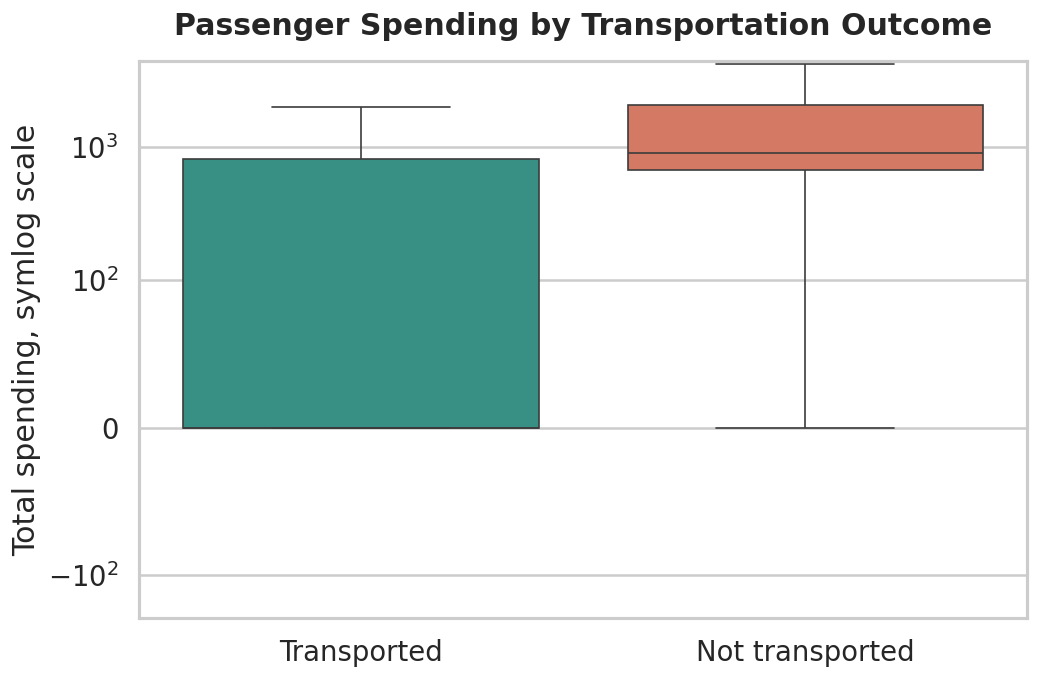

In [8]:
spending_plot_data = visual_data[[
    "TransportedLabel",
    "TotalSpending"
]].dropna()

fig, ax = plt.subplots(figsize=(9, 6))
sns.boxplot(
    data=spending_plot_data,
    x="TransportedLabel",
    y="TotalSpending",
    order=["Transported", "Not transported"],
    palette=[COLORS["transported"], COLORS["not_transported"]],
    showfliers=False,
    ax=ax
)
ax.set_yscale("symlog", linthresh=100)
ax.set_title("Passenger Spending by Transportation Outcome")
ax.set_xlabel("")
ax.set_ylabel("Total spending, symlog scale")
plt.tight_layout()
plt.savefig(DATA_DIR / "presentation_04_spending_boxplot.png", bbox_inches="tight")
plt.show()

## 8. Chart 5: Age and spending relationship

This scatter plot shows two numerical variables at once.

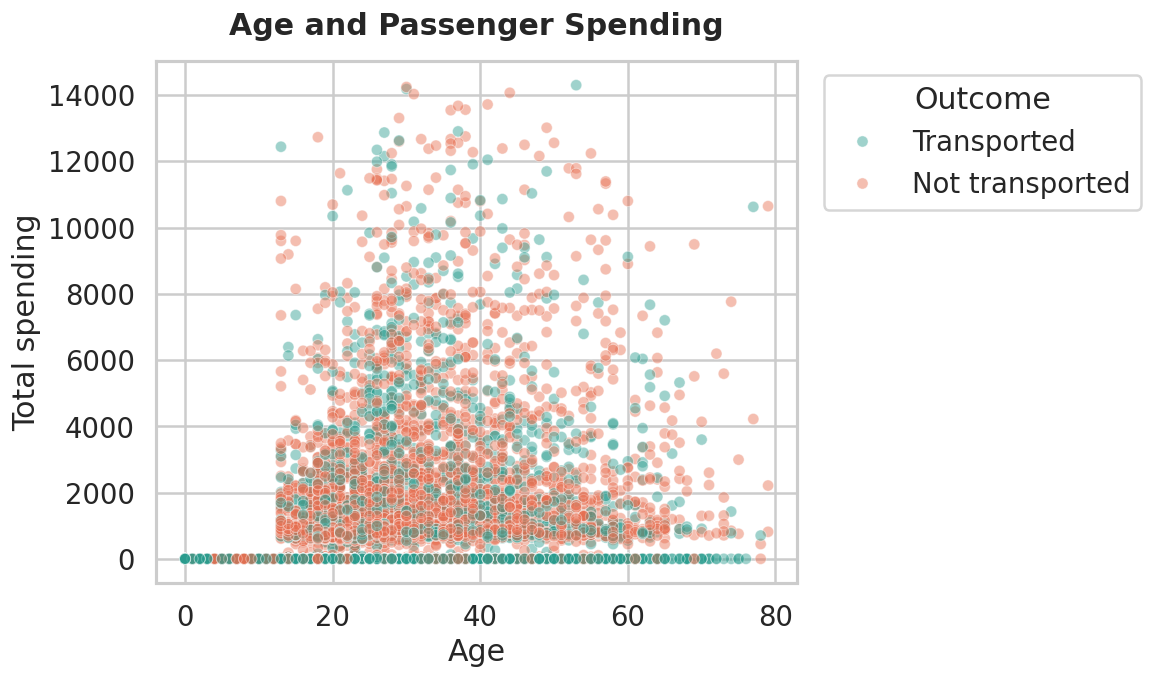

In [9]:
scatter_data = visual_data[[
    "Age",
    "TotalSpending",
    "TransportedLabel"
]].dropna()

spending_limit = scatter_data["TotalSpending"].quantile(0.99)
scatter_data = scatter_data[
    scatter_data["TotalSpending"] <= spending_limit
]

fig, ax = plt.subplots(figsize=(10, 6))
sns.scatterplot(
    data=scatter_data,
    x="Age",
    y="TotalSpending",
    hue="TransportedLabel",
    hue_order=["Transported", "Not transported"],
    palette=[COLORS["transported"], COLORS["not_transported"]],
    alpha=0.45,
    s=45,
    ax=ax
)
ax.set_title("Age and Passenger Spending")
ax.set_xlabel("Age")
ax.set_ylabel("Total spending")
ax.legend(title="Outcome", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.savefig(DATA_DIR / "presentation_05_age_spending_scatter.png", bbox_inches="tight")
plt.show()

## 9. Chart 6: Model comparison

This chart loads the model comparison file created by the Nov. 8 notebook.

In [10]:
comparison_path = DATA_DIR / "nov_8_model_comparison.csv"

if comparison_path.exists():
    model_results = pd.read_csv(comparison_path).sort_values(
        "Validation Accuracy",
        ascending=True
    )

    fig, ax = plt.subplots(figsize=(9, 5))
    bars = ax.barh(
        model_results["Model"],
        model_results["Validation Accuracy"],
        color=[
            COLORS["gold"] if value == model_results["Validation Accuracy"].max()
            else COLORS["blue"]
            for value in model_results["Validation Accuracy"]
        ]
    )
    ax.set_title("Validation Accuracy Across Candidate Models")
    ax.set_xlabel("Validation accuracy")
    ax.set_xlim(0.70, 0.85)

    for bar, value in zip(bars, model_results["Validation Accuracy"]):
        ax.text(
            value + 0.002,
            bar.get_y() + bar.get_height() / 2,
            f"{value:.3f}",
            va="center",
            fontsize=12
        )

    plt.tight_layout()
    plt.savefig(DATA_DIR / "presentation_06_model_comparison.png", bbox_inches="tight")
    plt.show()
else:
    print("Model comparison file not found.")
    print("Run the Nov. 8 notebook first, then run this cell again.")

Model comparison file not found.
Run the Nov. 8 notebook first, then run this cell again.


## 10. Optional chart: Group size and transportation

This chart connects the passenger ID structure to a passenger-level pattern.

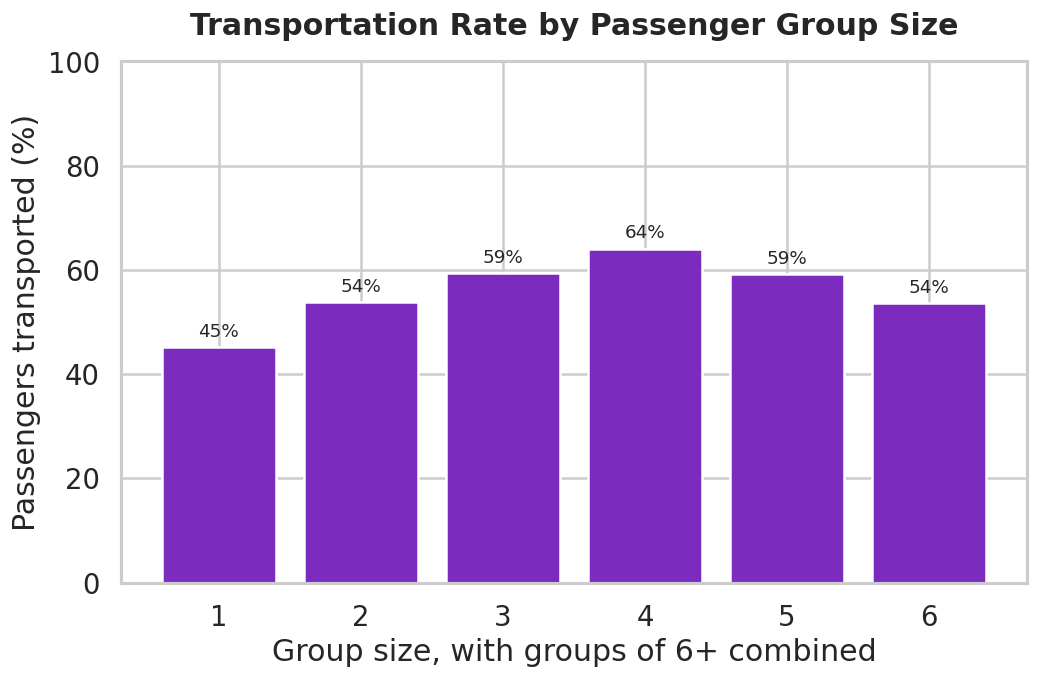

In [11]:
group_rates = (
    visual_data.assign(
        GroupSizeCapped=visual_data["GroupSize"].clip(upper=6)
    )
    .groupby("GroupSizeCapped")["Transported"]
    .mean()
    .mul(100)
)

fig, ax = plt.subplots(figsize=(9, 6))
bars = ax.bar(
    group_rates.index.astype(str),
    group_rates.values,
    color=COLORS["purple"]
)
ax.set_title("Transportation Rate by Passenger Group Size")
ax.set_xlabel("Group size, with groups of 6+ combined")
ax.set_ylabel("Passengers transported (%)")
ax.set_ylim(0, 100)

for bar, value in zip(bars, group_rates.values):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        value + 2,
        f"{value:.0f}%",
        ha="center",
        fontsize=11
    )

plt.tight_layout()
plt.savefig(DATA_DIR / "presentation_07_group_size_rates.png", bbox_inches="tight")
plt.show()